# Assignment 4 — Double ML and Meta-Learners
**Group 10** · ADSP 32029 Causal Models in Data Science

## Q5 (part 1): Average treatment effects via Double ML

**Big picture.** Double ML (DML) estimates the causal effect of a treatment `T` on the outcome `Y = stress_level`
in two steps: (1) use ML models to predict `Y` from covariates `X` and to predict `T` from `X`
(the *nuisance* models `model_y`, `model_t`), then (2) regress the leftover `Y` residual on the leftover `T` residual.
Whatever `X` explains about each is removed, which is how confounding by `X` is controlled.

* `LinearDML` — effect is a linear function of `X` (stable, narrow CIs, rigid).
* `CausalForestDML` — effect is a forest function of `X` (flexible, wider CIs).
* Nuisance learners: our Option 2 pair, a neural net (MLP) and gradient boosting (LightGBM), each used for both `model_y` and `model_t`.
* `X` for each treatment = DAG4 nodes that are not the treatment, the outcome, or a descendant of the treatment.

In [1]:
import sys
sys.path.insert(0, "src")

import pandas as pd
from dag import TREATMENTS, covariates_for
from nuisance import load_data
from pipeline import run_pipeline, plot_ates

pd.set_option("display.width", 140)
df = load_data()
df.shape

### Covariates used for each treatment (from DAG4)

In [2]:
for t in TREATMENTS:
    print(f"{t:<24} X = {covariates_for(t)}")

study_load               X = ['living_conditions', 'mental_health_history', 'noise_level', 'safety']
noise_level              X = ['academic_performance', 'future_career_concerns', 'living_conditions', 'mental_health_history', 'safety', 'study_load']
living_conditions        X = ['mental_health_history', 'safety', 'study_load']
academic_performance     X = ['living_conditions', 'mental_health_history', 'noise_level', 'safety', 'study_load']
future_career_concerns   X = ['academic_performance', 'living_conditions', 'mental_health_history', 'noise_level', 'safety', 'study_load']


### Fit all models (≈ 30 s, CPU)

In [3]:
res = run_pipeline(df, threshold=4, seed=42)

### Summary table: ATE with 95% confidence interval

In [4]:
res.round(3)

,treatment,estimator,nuisance,ate,se,ci_low,ci_high,significant
0,study_load,LinearDML,MLP,0.053,0.024,0.006,0.100,True
1,study_load,LinearDML,LightGBM,0.058,0.025,0.010,0.106,True
2,study_load,CausalForestDML,MLP,0.056,0.057,-0.055,0.168,False
3,study_load,CausalForestDML,LightGBM,0.063,0.062,-0.059,0.185,False
4,noise_level,LinearDML,MLP,0.065,0.024,0.017,0.113,True
5,noise_level,LinearDML,LightGBM,0.032,0.025,-0.017,0.081,False
6,noise_level,CausalForestDML,MLP,0.070,0.052,-0.033,0.173,False
7,noise_level,CausalForestDML,LightGBM,0.043,0.050,-0.055,0.141,False
8,living_conditions,LinearDML,MLP,-0.054,0.027,-0.107,-0.000,True
9,living_conditions,LinearDML,LightGBM,-0.034,0.026,-0.086,0.017,False


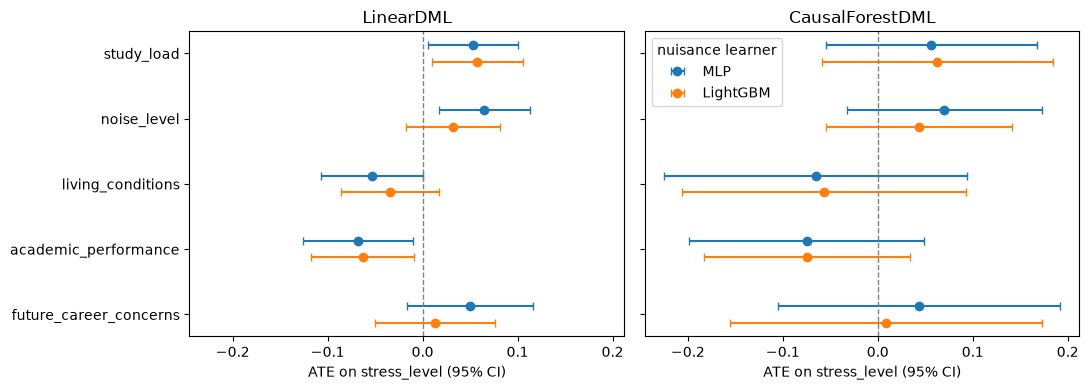

In [5]:
plot_ates(res);

### Reading the results

Units: `stress_level` runs 0–2, so an ATE of 0.05 means +0.05 stress points per one-step increase in the (0–5) treatment.

* **Effects are small.** Every ATE is within about ±0.08 stress points per step.
* **Signs are consistent across all four fits** for each treatment: `study_load` and `noise_level` push stress up;
  `living_conditions` and `academic_performance` push it down; `future_career_concerns` is near zero.
* **LinearDML is often "significant"; CausalForestDML never is.** The forest's CIs are roughly 2–3x wider
  because it estimates a much more flexible effect function. Only `study_load` and `academic_performance`
  have a 95% CI excluding zero under *both* nuisance learners (LinearDML). `noise_level` and `living_conditions`
  flip between significant and not depending on the nuisance learner, so treat them as suggestive.
* The nuisance learner matters less than the estimator choice, but it is not negligible for `noise_level` (0.065 vs 0.032 under LinearDML).

Caveat: these are causal only if DAG4 is right (and it is the densest candidate, per Assignment 3) and no unmeasured confounding remains.
Validation against naive ML models and refutation checks come in Q6–Q7.